In [68]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [69]:
models ={
     'Oracle-2 Omni (ZTF)': ['../../models/BTSv2-pro/fanciful-gorge-557',
                               '../../models/BTSv2-pro/flowing-dream-569',
                               '../../models/BTSv2-pro/exalted-aardvark-570',
                               '../../models/BTSv2-pro/glamorous-thunder-571',
                               '../../models/BTSv2-pro/morning-feather-572'],
    'Oracle-2 Omni (PS1)':['../../models/BTSv2-pro/woven-sweep-9',
                                # '../../models/BTSv2-pro/smooth-haze-141',
                                '../../models/BTSv2-pro/splendid-sun-142',
                                '../../models/BTSv2-pro/sweet-glade-143',
                                '../../models/BTSv2-pro/dazzling-thunder-144'
                                          ], 
}


colors = {
    'Oracle-2 Lite': '#994882',
    'Oracle-2': '#008080',
    'Oracle-2 Omni': '#FF6645',
    'Oracle-2 Omni (ZTF)': '#FF6645',
    'Oracle-2 Omni (PS1)': '#FF6645',
    'Image Backbone': "#666666",
    'Image Backbone (SC-ZTF)': "#666666",
    'Image Backbone (TC-PS)': "#666666",
}

markers = {
    'Oracle-2 Lite': 's',
    'Oracle-2': 'D',
    'Oracle-2 Omni': 'o',
    'Oracle-2 Omni (ZTF)': 'o',
    'Oracle-2 Omni (PS1)': 'o',
    'Image Backbone': '',
    'Image Backbone (SC-ZTF)': '',
    'Image Backbone (TC-PS)': '',
}

linestyles = {
    'Oracle-2 Lite': 'solid',
    'Oracle-2': 'solid',
    'Oracle-2 Omni': 'solid',
    'Oracle-2 Omni (ZTF)': 'solid',
    'Oracle-2 Omni (PS1)': 'dotted',
    'Image Backbone': 'solid',
    'Image Backbone (SC-ZTF)': 'dashed',
    'Image Backbone (TC-PS)': 'solid',
}

In [70]:
days = 2**np.arange(0, 11)

In [71]:
def get_data(model_path, c, stat, depth, days=days):

    data = []

    for day in days:


        path = f"{model_path}/reports/depth{depth}/report_trigger+{day}.csv"
        df = pd.read_csv(path)
        df_class = df[df['Class'] == c]
        value = df_class[stat].values[0]
        data.append(value)

    return np.array(data)
        

In [72]:
def get_model_stats(model_name, c, stat, depth, days=days):

    model_paths = models[model_name]
    model_data = np.zeros((len(model_paths), len(days))) 

    for i, model_path in enumerate(model_paths):
        print(f"Processing model: {model_name}, path: {model_path}")
        model_data[i,:] = get_data(model_path, c, stat, depth, days)

    return np.mean(model_data, axis=0), np.std(model_data, axis=0)


In [94]:
def plot_model_stats_multi_level(c, stat):

    # make the plots next to each other for depth in [1, 2]:
    plt.figure(figsize=(7, 4))
    depth = 2
    for model_name in models.keys():

        mean_f1, std_f1 = get_model_stats(model_name, c, stat, depth)

        plt.plot(days, mean_f1, label=model_name, linestyle=linestyles[model_name],color=colors[model_name], marker=markers[model_name], markeredgecolor='white', markersize=8)
        plt.fill_between(days, mean_f1 - std_f1, mean_f1 + std_f1, color=colors[model_name], alpha=0.2)


        plt.xscale('log')
        plt.grid(True, alpha=0.3)
        plt.xticks(days, labels=days)
        plt.xlabel('Days since first detection', fontsize='xx-large' )
        plt.ylabel("Macro F1", fontsize='xx-large')

        # reduce the number of ticks on the y-axis
        #plt.yticks(np.arange(0, 1.1, 0.2), labels=[f"{y:.1f}" for y in np.arange(0, 1.1, 0.2)], fontsize='x-large')

        # make ticks larger
        plt.tick_params(axis='both', which='major', labelsize='x-large')    
        

        # make a background box for the text
        plt.gca().text(0.9, 0.05, f'Depth {depth}', transform=plt.gca().transAxes, ha='center', fontsize='x-large', bbox=dict(facecolor='white', alpha=0.8, edgecolor='gray'))

    # Get handles and labels from the last axis to use in the figure legend
    handles, labels = plt.gca().get_legend_handles_labels()
    
    # Use fig.legend for centering across the whole figure
    fig = plt.gcf()
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.02), ncol=4, fontsize='large')
    
    # Adjust tight_layout to leave room for the legend at the bottom
    plt.tight_layout(rect=[0, 0.1, 1, 1])

    plt.savefig(f"BTS_F1.pdf", bbox_inches='tight')
    plt.savefig(f"BTS_F1.png", bbox_inches='tight', transparent=True)
    plt.show()

Processing model: Oracle-2 Omni (ZTF), path: ../../models/BTSv2-pro/fanciful-gorge-557
Processing model: Oracle-2 Omni (ZTF), path: ../../models/BTSv2-pro/flowing-dream-569
Processing model: Oracle-2 Omni (ZTF), path: ../../models/BTSv2-pro/exalted-aardvark-570
Processing model: Oracle-2 Omni (ZTF), path: ../../models/BTSv2-pro/glamorous-thunder-571
Processing model: Oracle-2 Omni (ZTF), path: ../../models/BTSv2-pro/morning-feather-572
Processing model: Oracle-2 Omni (PS1), path: ../../models/BTSv2-pro/woven-sweep-9
Processing model: Oracle-2 Omni (PS1), path: ../../models/BTSv2-pro/splendid-sun-142
Processing model: Oracle-2 Omni (PS1), path: ../../models/BTSv2-pro/sweet-glade-143
Processing model: Oracle-2 Omni (PS1), path: ../../models/BTSv2-pro/dazzling-thunder-144


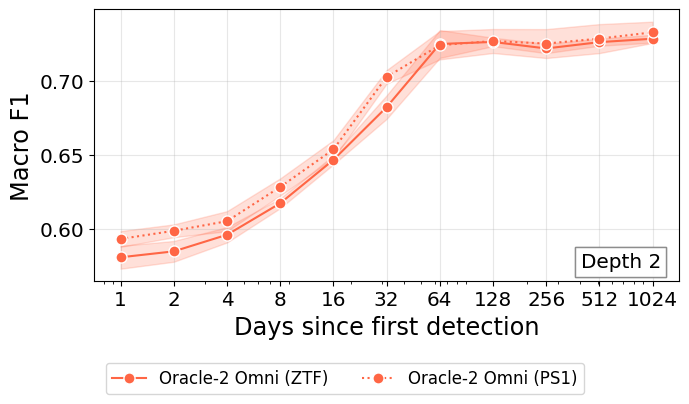

In [95]:
plot_model_stats_multi_level('macro avg', 'f1-score')

In [75]:
def plot_model_stats(c, stat, depth):

    plt.figure(figsize=(10, 6))
    for model_name in models.keys():

        if model_name == 'Oracle-2 Lite' or model_name == 'Oracle-2 Omni':
            continue

        mean_f1, std_f1 = get_model_stats(model_name, c, stat, depth)

        plt.plot(days, mean_f1, label=model_name, color=colors[model_name], marker=markers[model_name])
        plt.fill_between(days, mean_f1 - std_f1, mean_f1 + std_f1, color=colors[model_name], alpha=0.2)

    plt.xscale('log')
    plt.grid(True, alpha=0.3)
    plt.xticks(days, labels=days)
    plt.xlabel('Days')
    plt.ylabel(stat)
    plt.title(f'{stat} for class {c} at depth {depth}')
    plt.legend()
    plt.show()

In [76]:
def plot_model_F1s(c, stat, depth):

    plt.figure(figsize=(10, 6))

    mean_f1_l1, std_f1_l1 = get_model_stats("Oracle-2 Omni", 'macro avg', 'f1-score', 1)
    mean_f1_l2, std_f1_l2 = get_model_stats("Oracle-2 Omni", 'macro avg', 'f1-score', 2)

    plt.plot(days, mean_f1_l1, label="Depth 1", color=colors["Oracle-2 Omni"], marker='o', linestyle='dashed')
    plt.fill_between(days, mean_f1_l1 - std_f1_l1, mean_f1_l1 + std_f1_l1, color=colors["Oracle-2 Omni"], alpha=0.2)

    plt.plot(days, mean_f1_l2, label="Depth 2", color=colors["Oracle-2 Omni"], marker='s', linestyle='solid')
    plt.fill_between(days, mean_f1_l2 - std_f1_l2, mean_f1_l2 + std_f1_l2, color=colors["Oracle-2 Omni"], alpha=0.2)

    plt.xscale('log')
    #plt.grid(True, alpha=0.3)
    plt.xticks(days, labels=days)
    plt.xlabel('Days since first detection', fontsize='xx-large' )
    plt.ylabel('Macro F1', fontsize='xx-large')
    plt.title(f'Oracel-2 Omnni F1 score over time', fontsize='xx-large')
    plt.legend()

    plt.savefig(f"BTS_F1_Oracle2Omni.pdf", bbox_inches='tight')
    plt.savefig(f"BTS_F1_Oracle2Omni.png", bbox_inches='tight', transparent=True)

    plt.show()

In [77]:
plot_model_F1s('macro avg', 'f1-score', 1)

KeyError: 'Oracle-2 Omni'

<Figure size 1000x600 with 0 Axes>

Processing model: Oracle-2, path: ../../models/BTSv2/stilted-elevator-551
Processing model: Oracle-2, path: ../../models/BTSv2/firm-surf-561
Processing model: Oracle-2, path: ../../models/BTSv2/upbeat-pine-562
Processing model: Oracle-2, path: ../../models/BTSv2/chocolate-flower-563
Processing model: Oracle-2, path: ../../models/BTSv2/silvery-star-564
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/lilac-dew-556
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/playful-snow-573
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/clean-thunder-574
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/misunderstood-bush-575
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/eager-moon-576


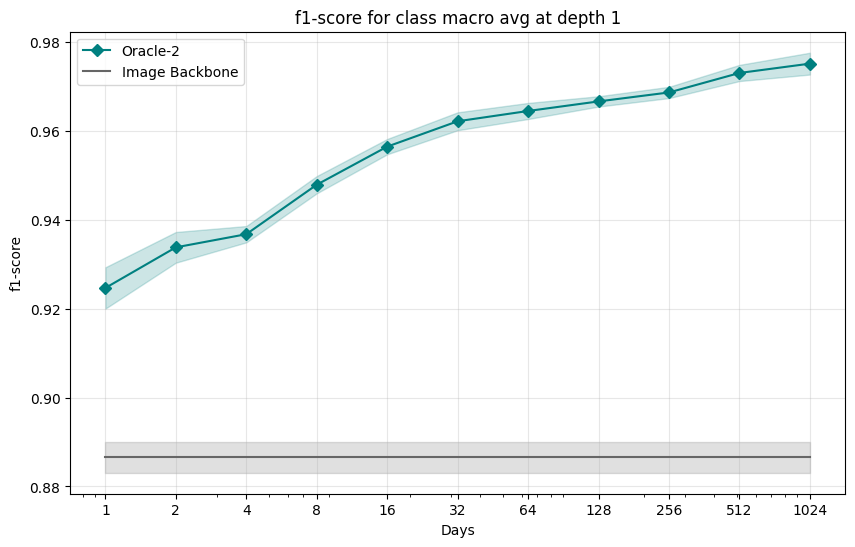

In [ ]:
plot_model_stats('macro avg', 'f1-score', 1)

Processing model: Oracle-2, path: ../../models/BTSv2/stilted-elevator-551
Processing model: Oracle-2, path: ../../models/BTSv2/firm-surf-561
Processing model: Oracle-2, path: ../../models/BTSv2/upbeat-pine-562
Processing model: Oracle-2, path: ../../models/BTSv2/chocolate-flower-563
Processing model: Oracle-2, path: ../../models/BTSv2/silvery-star-564
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/lilac-dew-556
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/playful-snow-573
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/clean-thunder-574
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/misunderstood-bush-575
Processing model: Image Backbone, path: ../../models/BTSv2_PSonly/eager-moon-576


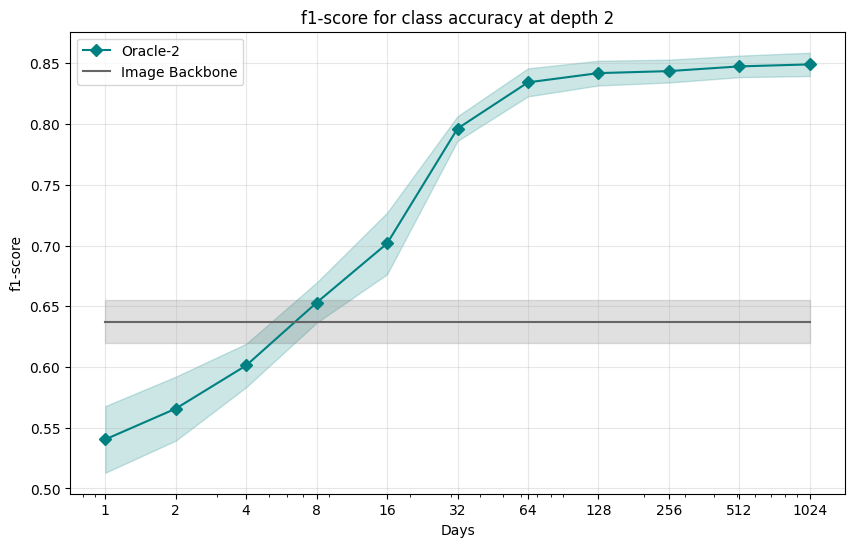

In [ ]:
plot_model_stats('accuracy', 'f1-score', 2)